# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Haseeb Hassan
- **Student ID:** 023-24-0274
- **Section:** H
- **GitHub:** [Haseeb-Hassan66](https://github.com/Haseeb-Hassan66)
- **Kaggle:** [haseebsamo66737](https://www.kaggle.com/haseebsamo66737)
- **Dataset:** Mall Customers (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

### Before You Start
- This lab does not reteach K-Means. It makes you use and test what you saw in the lecture. Each task gives the steps, not the code; the **Key definitions** table in each Part lists what you need.
- There is **no target column**: no train/test split and no accuracy. Judge every result by distances, silhouette, plots and common sense.
- Use `SEED = 42` everywhere. Write 1–3 lines of interpretation under every table and plot. A plot without an explanation earns no marks.
- Place `Mall_Customers.csv` in the same folder as this notebook (or upload it to Colab).
- Time: about 2 hours 15 minutes of work. Use the remaining time to finish answers, run the notebook top to bottom and submit.

---

## Part 0 — Setup and First Look (10 minutes)

Load the data and look at it before you cluster anything.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |

**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.

In [2]:
df = pd.read_csv('Mall_Customers.csv')
df = df.rename(columns={'Annual Income (k$)': 'Income', 'Spending Score (1-100)': 'Spending'})

print('Shape:', df.shape)
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print()
print(df['Gender'].value_counts())
print()
df[['Age', 'Income', 'Spending']].describe()

Shape: (200, 5)
Missing values: 0
Duplicate rows: 0

Gender
Female    112
Male       88
Name: count, dtype: int64



,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first.

1. Draw one scatter plot of Spending vs Income, with axis labels and a title.

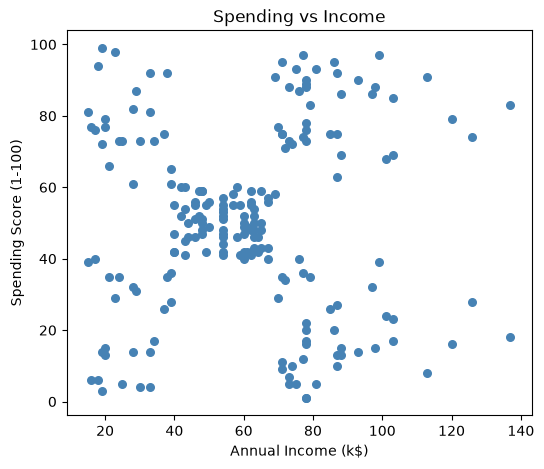

In [3]:
plt.figure(figsize=(6, 5))
plt.scatter(df['Income'], df['Spending'], s=30, color='steelblue')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Spending vs Income')
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye? Describe them in one line each (e.g. 'high income, low spending').

(b) Why can we not use accuracy or a train/test split to judge a clustering result?

**Your answers:**

(a) I can see five groups. The first group has low income and low spending and sits at the bottom left. The second group has low income and high spending and sits at the top left. The third group has medium income and medium spending and sits in the middle. The fourth group has high income and low spending and sits at the bottom right. The fifth group has high income and high spending and sits at the top right.

(b) Because there is no target column, there is no label to compare the clusters with. Accuracy needs labels and a train/test split, which only works when we are predicting something. In clustering we can only check how tight and distinct the clusters are using inertia, silhouette or visual plots.

---

## Part 1 — K-Means From Scratch (30 minutes)

In the lecture you did K-Means by hand. Here you turn those steps into code and check your own function against scikit-learn. Using `KMeans()` inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: \|x - m\|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |

### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: `np.abs(x[:, None] - m[None, :])` has shape (9, 2).
- Cluster of each point: `dist.argmin(axis=1)`.

In [4]:
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4, 11], dtype=float)   # starting centroids

it = 0
while True:
    it += 1
    dist = np.abs(x[:, None] - m[None, :])      # shape (9, 2)
    labels = dist.argmin(axis=1)                # assign step
    new_m = np.array([x[labels == k].mean() for k in range(2)])   # update step

    print('Iteration', it)
    print('  C1:', x[labels == 0], ' C2:', x[labels == 1])
    print('  new centroids:', new_m)

    if np.allclose(new_m, m):
        break
    m = new_m

inertia = ((x - m[labels]) ** 2).sum()
print()
print('Final centroids:', m)
print('Inertia:', inertia)
print('Lecture slides: centroids 7 and 25, inertia 150')

Iteration 1
  C1: [2. 4. 3.]  C2: [10. 12. 20. 30. 11. 25.]
  new centroids: [ 3. 18.]
Iteration 2
  C1: [ 2.  4. 10.  3.]  C2: [12. 20. 30. 11. 25.]
  new centroids: [ 4.75 19.6 ]
Iteration 3
  C1: [ 2.  4. 10. 12.  3. 11.]  C2: [20. 30. 25.]
  new centroids: [ 7. 25.]
Iteration 4
  C1: [ 2.  4. 10. 12.  3. 11.]  C2: [20. 30. 25.]
  new centroids: [ 7. 25.]

Final centroids: [ 7. 25.]
Inertia: 150.0
Lecture slides: centroids 7 and 25, inertia 150


### Task 1.2 — Your own K-Means function vs scikit-learn

Turn your loop into a function, then show it gives the same answer as scikit-learn.

1. Write `my_kmeans(X, init_centroids, max_iter=100)` that works for any number of features and returns labels, centroids, inertia and the number of iterations. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
2. Use X2 = Income and Spending (200 x 2) with the first 5 rows as starting centroids. Run `my_kmeans` and `KMeans(n_clusters=5, init=<the same 5 rows>, n_init=1, tol=0, algorithm='lloyd')`, then compare the inertia and the centroids.

In [5]:
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    c = np.asarray(init_centroids, dtype=float)
    if c.ndim == 1:
        c = c.reshape(-1, 1)
    k = c.shape[0]

    n_iter = 0
    for i in range(max_iter):
        n_iter += 1
        # distances of every point to every centroid
        d = np.sqrt(((X[:, None, :] - c[None, :, :]) ** 2).sum(axis=2))
        labels = d.argmin(axis=1)
        new_c = c.copy()
        for j in range(k):
            if np.any(labels == j):          # keep old centroid if a cluster gets empty
                new_c[j] = X[labels == j].mean(axis=0)
        if np.allclose(new_c, c):
            break
        c = new_c

    inertia = ((X - c[labels]) ** 2).sum()
    return labels, c, inertia, n_iter


# test on Example 1
lab, cen, inert, n = my_kmeans(x, [4, 11])
print('Example 1 -> centroids:', cen.ravel(), ' inertia:', inert, ' iterations:', n)

Example 1 -> centroids: [ 7. 25.]  inertia: 150.0  iterations: 4


In [6]:
X2 = df[['Income', 'Spending']].values.astype(float)
init5 = X2[:5].copy()                       # first 5 rows as starting centroids

lab_my, cen_my, inert_my, n_my = my_kmeans(X2, init5)

km = KMeans(n_clusters=5, init=init5, n_init=1, tol=0, algorithm='lloyd')
km.fit(X2)

print('My inertia     :', round(inert_my, 4), ' iterations:', n_my)
print('sklearn inertia:', round(km.inertia_, 4), ' iterations:', km.n_iter_)
print('Same labels    :', np.array_equal(lab_my, km.labels_))
print('Centroids match:', np.allclose(cen_my, km.cluster_centers_))
print()
print('My centroids:')
print(np.round(cen_my, 3))
print('sklearn centroids:')
print(np.round(km.cluster_centers_, 3))

My inertia     : 44448.4554  iterations: 4
sklearn inertia: 44448.4554  iterations: 4
Same labels    : True
Centroids match: True

My centroids:
[[26.304 20.913]
 [25.727 79.364]
 [88.2   17.114]
 [86.538 82.128]
 [55.296 49.519]]
sklearn centroids:
[[26.304 20.913]
 [25.727 79.364]
 [88.2   17.114]
 [86.538 82.128]
 [55.296 49.519]]


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn? If anything differed, explain why.

**Your answers:**

(a) In iteration 1 the centroids became 3 and 18. The distance from 10 to 3 is 7 and the distance from 10 to 18 is 8. So 10 is now closer to 3, which means it moved to cluster C1. At the beginning the centroids were 4 and 11. The distance from 10 to 11 was 1, so 10 was originally closer to 11 and was in cluster C2.

(b) The loop stops when the centroids and the clusters no longer change. In Example 1 this happened at iteration 4 where the centroids were 7 and 25. The algorithm always stops because each assignment and update step either keeps the inertia the same or reduces it. Since there are only a finite number of ways to group the points, the process must end. But it only reaches the nearest local minimum from the starting centroids, so it doesn't always find the best possible solution.

(c) Yes, it matched. Both methods gave the same inertia: 44448.4554. The labels were identical, the five centroids were the same, and both took exactly 4 iterations. I used the same starting rows and set tol=0, so both followed the exact same steps. On Example 1 my function also produced centroids 7 and 25 with an inertia of 150.

---

## Part 2 — Choosing K: Elbow and Silhouette (25 minutes)

Nobody tells us K. Use the two lecture tools, the elbow and the silhouette, then calculate one silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |

### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit `KMeans(n_clusters=K, n_init=10, random_state=SEED)` and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.

 K   Inertia  Silhouette
 2 181363.60      0.2969
 3 106348.37      0.4676
 4  73679.79      0.4932
 5  44448.46      0.5539
 6  37233.81      0.5398
 7  30241.34      0.5288
 8  25036.42      0.4548
 9  21916.79      0.4561
10  20072.07      0.4411


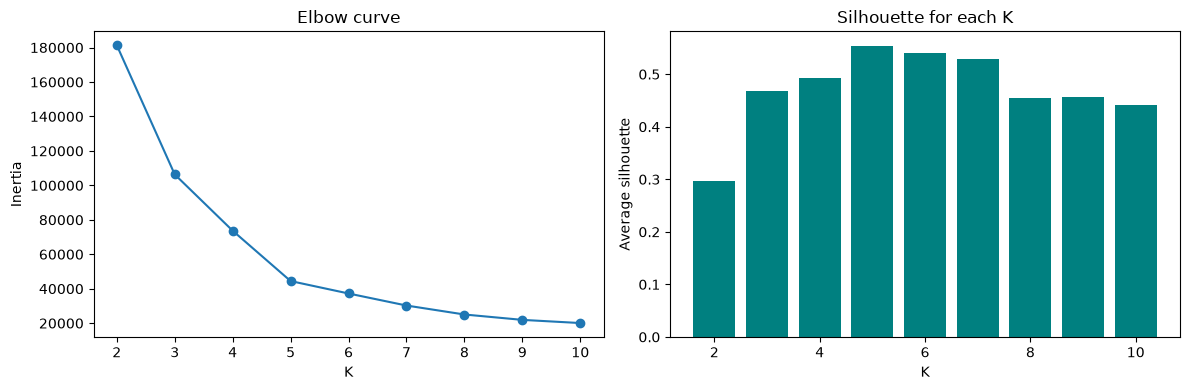

K with highest silhouette: 5 -> 0.5539


In [7]:
ks = list(range(2, 11))
inertias, sils = [], []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X2)
    inertias.append(model.inertia_)
    sils.append(silhouette_score(X2, model.labels_))

res = pd.DataFrame({'K': ks, 'Inertia': np.round(inertias, 2), 'Silhouette': np.round(sils, 4)})
print(res.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker='o')
ax[0].set_xlabel('K')
ax[0].set_ylabel('Inertia')
ax[0].set_title('Elbow curve')
ax[1].bar(ks, sils, color='teal')
ax[1].set_xlabel('K')
ax[1].set_ylabel('Average silhouette')
ax[1].set_title('Silhouette for each K')
plt.tight_layout()
plt.show()

best_k = ks[int(np.argmax(sils))]
print('K with highest silhouette:', best_k, '->', round(max(sils), 4))

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point, using only NumPy distances. Apply it to customer 1 (row 0) and compare with `silhouette_samples`.

In [8]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
lab5 = km5.labels_

def silhouette_one(X, labels, i):
    d = np.sqrt(((X - X[i]) ** 2).sum(axis=1))      # distance from point i to all points
    own = labels[i]
    same = (labels == own)
    same[i] = False                                  # leave the point itself out
    a = d[same].mean()
    b = min(d[labels == c].mean() for c in np.unique(labels) if c != own)
    s = (b - a) / max(a, b)
    return a, b, s

a, b, s = silhouette_one(X2, lab5, 0)
print('Customer 1 (row 0): a =', round(a, 4), ' b =', round(b, 4), ' s =', round(s, 4))
print('silhouette_samples :', round(silhouette_samples(X2, lab5)[0], 4))
print('Same value:', np.isclose(s, silhouette_samples(X2, lab5)[0]))

Customer 1 (row 0): a = 24.6404  b = 42.2653  s = 0.417
silhouette_samples : 0.417
Same value: True


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote your numbers.

(b) What is the silhouette of customer 1, and what does it tell you about where that customer sits?

(c) Why should we never choose K only by the lowest inertia?

**Your answers:**

(a) The elbow suggests K = 5. The inertia drops a lot until K = 5 (73679.8 at K=4 to 44448.5 at K=5). After that the drop is small (37233.8 at K=6, 30241.3 at K=7). The silhouette is also highest at K = 5 (0.5539). So both agree on K = 5.

(b) For customer 1, a = 24.64, b = 42.27 and s = 0.417, which is the same as silhouette_samples. It is positive and fairly high. The customer is in the right cluster and is closer to its own cluster than to the next nearest cluster. It is not very close to 1, so it is not deep inside the cluster either.

(c) Because inertia always goes down when K increases. The lowest inertia will always choose the biggest K (K=10 gave 20072.1 and K=200 would give 0). That just splits real groups into small pieces. The silhouette actually dropped to 0.4411 at K=10, so more clusters were not better.

---

## Part 3 — Starting Points and Stability (15 minutes)

The lecture said 'starting points matter — run several starts and keep the best'. Here you measure how much.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |

### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in two settings: `init='random'` with `n_init=1`, and `init='k-means++'` with `n_init=10`.
2. For each setting print the lowest and the highest final inertia and the number of distinct values (round to 1 decimal).

In [9]:
def run_30(init, n_init):
    out = []
    for seed in range(30):
        m_ = KMeans(n_clusters=5, init=init, n_init=n_init, random_state=seed).fit(X2)
        out.append(m_.inertia_)
    return np.array(out)

in_random = run_30('random', 1)
in_pp = run_30('k-means++', 10)

for name, arr in [("init='random', n_init=1", in_random), ("init='k-means++', n_init=10", in_pp)]:
    r = np.round(arr, 1)
    print(name)
    print('  lowest :', r.min())
    print('  highest:', r.max())
    print('  distinct values:', len(np.unique(r)))
    print('  distinct list:', np.unique(r))
    print('  runs that hit the lowest value:', int((r == r.min()).sum()), 'out of 30')
    print()

init='random', n_init=1
  lowest : 44448.5
  highest: 91762.0
  distinct values: 14
  distinct list: [44448.5 44454.5 66532.  66674.4 66698.1 66733.4 66790.3 67789.3 67818.5
 70096.4 75036.5 75582.7 89897.5 91762. ]
  runs that hit the lowest value: 10 out of 30

init='k-means++', n_init=10
  lowest : 44448.5
  highest: 44448.5
  distinct values: 1
  distinct list: [44448.5]
  runs that hit the lowest value: 30 out of 30



**Questions** (answer with your own numbers)

(a) How many different final inertia values did each setting produce?

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init solve this problem? Use your numbers.

**Your answers:**

(a) init='random' with n_init=1 gave 14 different final inertia values. init='k-means++' with n_init=10 gave only one final inertia value (44448.5).

(b) Because the starting centroids are chosen randomly and K-Means only improves from where it starts, a bad start can get stuck in a local minimum. Different seeds can end in different solutions even with the same data and the same K.

(c) With random start the inertia ranged from 44448.5 to 91762.0 and only 10 out of 30 runs found the best value. k-means++ picks starting centroids that are far from each other, so the starts are better. With n_init=10 the algorithm runs 10 starts and keeps the one with the lowest inertia. Because of this all 30 runs gave an inertia of 44448.5.

---

## Part 4 — Scaling: Units Decide the Clusters (20 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it by changing only the unit of Income.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |

### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, `n_init=10`, `random_state=SEED`).
2. Print the ARI between raw k$ and raw dollars, and between scaled k$ and scaled dollars.
3. Draw Age vs Income (in k$) twice: coloured by the raw-dollar clusters and by the scaled clusters.

In [10]:
Xa = df[['Age', 'Income']].values.astype(float)       # Income in k$
Xb = Xa.copy()
Xb[:, 1] = Xb[:, 1] * 1000                             # Income in dollars

def fit4(X, scale):
    if scale:
        X = StandardScaler().fit_transform(X)
    return KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X).labels_

lab_raw_k = fit4(Xa, False)
lab_raw_d = fit4(Xb, False)
lab_sc_k = fit4(Xa, True)
lab_sc_d = fit4(Xb, True)

print('ARI raw k$ vs raw dollars    :', round(adjusted_rand_score(lab_raw_k, lab_raw_d), 4))
print('ARI scaled k$ vs scaled dollars:', round(adjusted_rand_score(lab_sc_k, lab_sc_d), 4))

# extra check: how different are the raw ones in terms of the sizes
print()
print('Cluster sizes raw k$      :', np.bincount(lab_raw_k))
print('Cluster sizes raw dollars :', np.bincount(lab_raw_d))
print('Cluster sizes scaled      :', np.bincount(lab_sc_d))

ARI raw k$ vs raw dollars    : 0.4897
ARI scaled k$ vs scaled dollars: 1.0

Cluster sizes raw k$      : [56 73 47 24]
Cluster sizes raw dollars : [50 62 68 20]
Cluster sizes scaled      : [60 62 43 35]


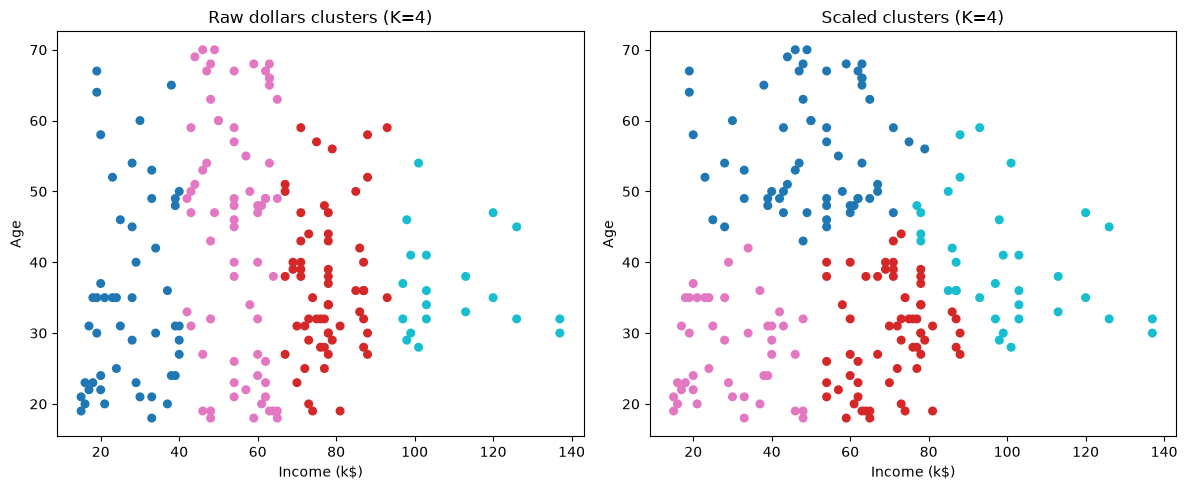

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(Xa[:, 1], Xa[:, 0], c=lab_raw_d, cmap='tab10', s=30)
ax[0].set_title('Raw dollars clusters (K=4)')
ax[0].set_xlabel('Income (k$)')
ax[0].set_ylabel('Age')
ax[1].scatter(Xa[:, 1], Xa[:, 0], c=lab_sc_d, cmap='tab10', s=30)
ax[1].set_title('Scaled clusters (K=4)')
ax[1].set_xlabel('Income (k$)')
ax[1].set_ylabel('Age')
plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula: which feature controls the distance now? What did scaling fix?

(b) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.

**Your answers:**

(a) When the unit of income was changed to dollars the clusters changed a lot. The ARI between the raw k$ clusters and the raw dollars clusters is only 0.4897. The distance is calculated as the square root of the sum of the squared differences in age and income. In dollars the income differences are in the thousands (like 10000) while age differences are only in the tens. Because of this income dominates the distance and age is nearly ignored. As a result the clusters in dollars ended up being just income groups: 15-40k, 42-65k, 67-93k and 97-137k. After scaling, each feature has a mean of 0 and a standard deviation of 1, so the unit does not affect the distance anymore. The ARI between the scaled k$ and the scaled dollars clusters is 1.0, which shows that the clusters are identical.

(b) I will check the units and ranges of the features using describe(). If the features have different units or very different ranges, I will scale them. I would not scale only if all features are already on the same scale and have similar meanings.

---

## Part 5 — Outliers (15 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and catch it with a simple distance rule.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |

### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (`n_init=10`, `random_state=SEED`) without and with the extra customer.
2. Print the cluster sizes and the centroids (sorted by income) for both fits.
3. Draw the two clusterings side by side.

WITHOUT extra customer (200 rows)
  sizes    : [22 23 81 39 35]
  centroids (Income, Spending):
[[25.7 79.4]
 [26.3 20.9]
 [55.3 49.5]
 [86.5 82.1]
 [88.2 17.1]]

WITH extra customer (201 rows)
  sizes    : [ 23 100  39  38   1]
  centroids (Income, Spending):
[[ 26.3  20.9]
 [ 48.3  56.5]
 [ 86.5  82.1]
 [ 87.   18.6]
 [400.   99. ]]



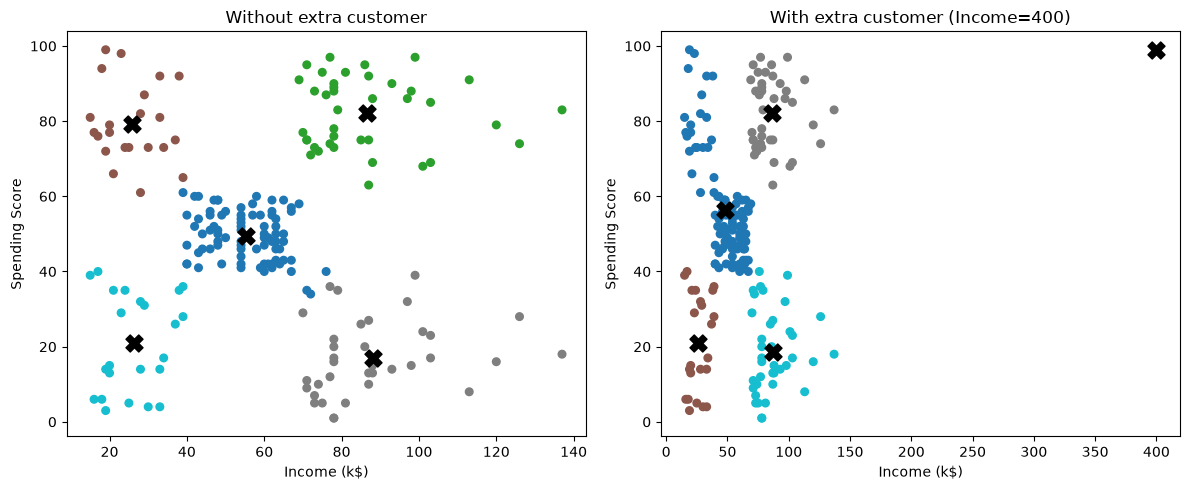

In [12]:
extra = np.array([[400, 99]], dtype=float)
X2_out = np.vstack([X2, extra])

km_a = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_b = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_out)

def show(model, name):
    order = np.argsort(model.cluster_centers_[:, 0])           # sort by income
    sizes = np.bincount(model.labels_, minlength=5)[order]
    cents = model.cluster_centers_[order]
    print(name)
    print('  sizes    :', sizes)
    print('  centroids (Income, Spending):')
    print(np.round(cents, 1))
    print()

show(km_a, 'WITHOUT extra customer (200 rows)')
show(km_b, 'WITH extra customer (201 rows)')

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X2[:, 0], X2[:, 1], c=km_a.labels_, cmap='tab10', s=30)
ax[0].scatter(km_a.cluster_centers_[:, 0], km_a.cluster_centers_[:, 1], c='black', marker='X', s=150)
ax[0].set_title('Without extra customer')
ax[1].scatter(X2_out[:, 0], X2_out[:, 1], c=km_b.labels_, cmap='tab10', s=30)
ax[1].scatter(km_b.cluster_centers_[:, 0], km_b.cluster_centers_[:, 1], c='black', marker='X', s=150)
ax[1].set_title('With extra customer (Income=400)')
for a_ in ax:
    a_.set_xlabel('Income (k$)')
    a_.set_ylabel('Spending Score')
plt.tight_layout()
plt.show()

### Task 5.2 — Catch it with a distance rule

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). Is the extra customer flagged? Are any real customers flagged?

In [13]:
d_all = km_a.transform(X2).min(axis=1)                  # distance to nearest centroid, 200 real customers
d_extra = km_a.transform(extra).min(axis=1)[0]          # extra customer, same model

thr = d_all.mean() + 3 * d_all.std()
print('Mean distance :', round(d_all.mean(), 2))
print('Std distance  :', round(d_all.std(), 2))
print('Threshold (mean + 3 std):', round(thr, 2))
print()
print('Extra customer distance:', round(d_extra, 2), '-> flagged:', bool(d_extra > thr))

flag = d_all > thr
print('Real customers flagged:', int(flag.sum()))
if flag.sum() > 0:
    print(df.loc[flag, ['CustomerID', 'Age', 'Income', 'Spending']].assign(Distance=np.round(d_all[flag], 2)).to_string(index=False))

Mean distance : 13.02
Std distance  : 7.26
Threshold (mean + 3 std): 34.8

Extra customer distance: 313.92 -> flagged: True
Real customers flagged: 4
 CustomerID  Age  Income  Spending  Distance
        197   45     126        28     39.34
        198   32     126        74     40.29
        199   32     137        18     48.81
        200   30     137        83     50.47


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Use the sizes and centroids.

(b) Did the rule catch the extra customer? If real customers were flagged too, are they errors or simply unusual customers?

(c) Name two ways to deal with outliers and one risk of simply deleting them.

**Your answers:**

(a) One customer took a cluster by itself (size 1, centroid at income 400 and spending 99). Since K was fixed at 5, the other customers had to be placed into 4 clusters. The cluster sizes changed from [22 23 81 39 35] to [23 100 39 38 1]. The low income high spending group (22) and the middle group (81) mostly combined into one large cluster of size 100 with centroid at (48.3, 56.5). This made the segments worse because of one single point.

(b) Yes, the extra customer had a distance of 313.92, which is well above the threshold of 34.80, so it was flagged. The rule also flagged 4 real customers (CustomerID 197 to 200, income 126 to 137, distances 39 to 50). These are not errors. They are customers with very high income sitting at the edge of the data. They are unusual, not wrong.

(c) Two ways to handle outliers are: check them and remove them only if they are errors, or reduce their impact by capping the values, using a log transform, or switching to a method that is less sensitive to outliers, like K-Medoids. The risk of simply deleting them is that we might remove real customers who are important. For example the 4 high income customers might be valuable, and removing them would mean our segments no longer represent all types of customers.

---

## Part 6 — Name the Segments and Wrap-Up (20 minutes)

Turn your clusters into segments that a marketing team could use.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Segment profile | The average Age, Income and Spending of each cluster. It tells you who is in the group. | `df.groupby('Cluster')[['Age','Income','Spending']].mean()` |
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |

### Task 6.1 — Profile and name the segments

Use the K you chose in Part 2 and the Income and Spending features.

1. Fit the final model (`n_init=10`, `random_state=SEED`) and add a Cluster column to the DataFrame.
2. Show the size and the mean Age, Income and Spending of each cluster.
3. Give each cluster a short name (e.g. 'High income, low spending') and one marketing action. Store the name in a Segment column.

In [14]:
K_FINAL = 5
final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED).fit(X2)
df['Cluster'] = final.labels_

profile = df.groupby('Cluster').agg(Size=('CustomerID', 'count'),
                                    Age=('Age', 'mean'),
                                    Income=('Income', 'mean'),
                                    Spending=('Spending', 'mean')).round(1)
print(profile)

# name each cluster from its average income and spending
def level(v, low, high):
    return 'low' if v < low else ('high' if v >= high else 'medium')

names = {}
for c in profile.index:
    inc = level(profile.loc[c, 'Income'], 40, 70)
    spd = level(profile.loc[c, 'Spending'], 40, 60)
    names[c] = f'{inc.capitalize()} income, {spd} spending'

df['Segment'] = df['Cluster'].map(names)
print()
print(df.groupby(['Cluster', 'Segment']).size())

         Size   Age  Income  Spending
Cluster                              
0          81  42.7    55.3      49.5
1          39  32.7    86.5      82.1
2          22  25.3    25.7      79.4
3          35  41.1    88.2      17.1
4          23  45.2    26.3      20.9

Cluster  Segment                       
0        Medium income, medium spending    81
1        High income, high spending        39
2        Low income, high spending         22
3        High income, low spending         35
4        Low income, low spending          23
dtype: int64


**Segment names and actions** (one line per cluster)

| Cluster | Segment name | Marketing action |
|---|---|---|
| 0 | Medium income, medium spending (81 customers) | Loyalty points and bundle offers to slowly increase their spending |
| 1 | High income, high spending (39 customers) | VIP membership and early access to new products |
| 2 | Low income, high spending (22 customers) | Discount coupons and sale alerts to keep them buying |
| 3 | High income, low spending (35 customers) | Personalised premium offers and a survey to find what they want |
| 4 | Low income, low spending (23 customers) | Only low cost marketing like occasional discount emails |

### Task 6.2 — Save and summarise

Produce a file someone else can use without running your notebook.

1. Save `customer_segments.csv` with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.
2. Write a 4–6 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, how you handled scaling and outliers, and one limitation.

In [15]:
out = df[['CustomerID', 'Age', 'Gender', 'Income', 'Spending', 'Cluster', 'Segment']]
out.to_csv('customer_segments.csv', index=False)
print(out.shape)
out.head()

(200, 7)


,CustomerID,Age,Gender,Income,Spending,Cluster,Segment
0,1,19,Male,15,39,4,"Low income, low spending"
1,2,21,Male,15,81,2,"Low income, high spending"
2,3,20,Female,16,6,4,"Low income, low spending"
3,4,23,Female,16,77,2,"Low income, high spending"
4,5,31,Female,17,40,4,"Low income, low spending"


**Executive Summary** (4–6 lines)

I chose K = 5 using Income and Spending because the elbow method shows a bend at K = 5 and the silhouette score is highest there at 0.5539. The resulting segments are: medium income and medium spending with 81 customers, high income and high spending with 39 customers, high income and low spending with 35 customers, low income and low spending with 23 customers, and low income and high spending with 22 customers. For scaling I only used Income and Spending since they are on similar ranges, and Part 4 showed that features in different units must be scaled. For outliers I applied the distance rule (mean plus three std), which identified the one extreme customer (313.92 vs 34.80), but it also flagged four real high income customers so I decided to keep them. A limitation of this analysis is that the data set only has 200 customers and two features. With more data or additional features like Age, the segments might change.

---

### Before you submit
- [x] Restart the kernel and **Run All**: the notebook runs top to bottom without errors.
- [x] Every table and plot has 1–3 lines of interpretation below it.
- [x] All questions are answered with your own numbers.
- [x] Student Information block is filled in.
- [x] Notebook and `customer_segments.csv` are pushed to your GitHub repository.